In [1]:
class Value:
    def __init__(self, data, _children=(), _op=None, label='', _grad=0.0):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self._grad = _grad
        self._backward = lambda: None
        

    def __add__(self, other):
        if not isinstance(other, Value):
            other = Value(other)

        out = Value(self.data + other.data, (self, other), "+")

        def _backward():
            self._grad += 1 * out._grad
            other._grad += 1 * out._grad
            
        out._backward = _backward

        return out

    def __radd__(self, other):
        return self + other

    def __mul__(self, other):
        if not isinstance(other, Value):
            other = Value(other)

        out = Value(self.data * other.data, (self, other), "*")
        def _backward():
            self._grad += other.data * out._grad
            other._grad += self.data * out._grad

        out._backward = _backward
        return out

    def __rmul__(self, other):
        return self * other

    def backward(self):
        topo = []
        visited = set()
        def build_topo(root):
            if root not in visited:
                visited.add(root)
                for child in root._prev:
                    build_topo(child)
                topo.append(root)
                
        build_topo(self)
        
        self._grad = 1.0
        for n in reversed(topo):
            n._backward()

    def __repr__(self):
        return f"Value(data={self.data})"

In [2]:
a = Value(3, label='a')
b = Value(2, label='b')
c = Value(-1, label='c')

e = (a + b); e.label='e'
d = e * c ; d.label='d'
f = Value(-2.0, label='f')
L = d * f; L.label='L'
print( d )

Value(data=-5)


In [3]:
d._prev

{Value(data=-1), Value(data=5)}

In [4]:
d._op

'*'

In [5]:
!pip install graphviz

In [6]:
from collections import deque

def build_graph(root):
    nodes = set([root])
    edges = set()
    for child in root._prev:
        edges.add((child, root))

    children = deque(root._prev)
    while children:
        child = children.popleft()
        if child not in nodes:
            for grandchild in child._prev:
                children.append(grandchild)
                edges.add((grandchild, child))
            nodes.add(child)
    return (nodes, edges)
            
        

In [7]:
nodes = build_graph(L)
print(nodes)

({Value(data=-2.0), Value(data=-1), Value(data=3), Value(data=-5), Value(data=2), Value(data=5), Value(data=10.0)}, {(Value(data=-2.0), Value(data=10.0)), (Value(data=-1), Value(data=-5)), (Value(data=2), Value(data=5)), (Value(data=-5), Value(data=10.0)), (Value(data=3), Value(data=5)), (Value(data=5), Value(data=-5))})


In [8]:
from graphviz import Digraph
def draw_graph(root):
    g = Digraph(format='svg', graph_attr={'rankdir': 'LR'})
    nodes, edges = build_graph(root)
    
    for node in nodes:
        uid = str(id(node))
        g.node(name = uid, label = "{%s | data %.4f | grad %.4f}" % (node.label, node.data, node._grad), shape='record')
        
        if node._op:
            g.node(name = uid + node._op, label=node._op)
            g.edge(uid+node._op, uid)

    for l, r in edges:
        
        g.edge(str(id(l)), str(id(r))+r._op)
        
    return g
        

Fontconfig warning: We will not regenerate the cache because some cache files were generated by a newer version (0x2012003) of Fontconfig. Please regenerate the cache with the latest version of Fontconfig to avoid any unexpected behavior. (current version: 0x2012002)


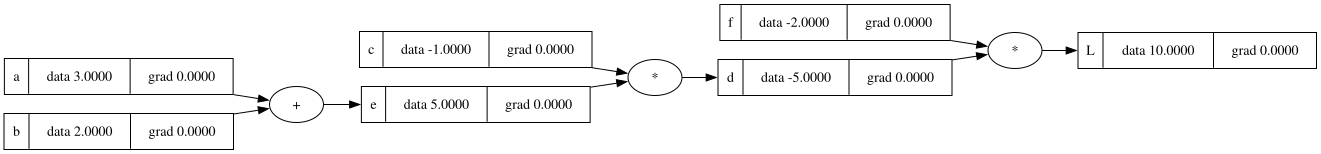

In [9]:
draw_graph(L)

In [10]:
# a simple neuron
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

w1 = Value(-3.0, label='w1')
w2 = Value(1.0 , label='w2')
b = Value(6.7, label='b')

x1w1 = x1*w1; x1w1.label='x1 * w1'
x2w2 = x2*w2; x2w2.label='x2 * w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

n = x1w1x2w2 + b; n.label='n'

In [11]:
n._grad=1.0

In [12]:
n._backward()
x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()

Fontconfig warning: We will not regenerate the cache because some cache files were generated by a newer version (0x2012003) of Fontconfig. Please regenerate the cache with the latest version of Fontconfig to avoid any unexpected behavior. (current version: 0x2012002)


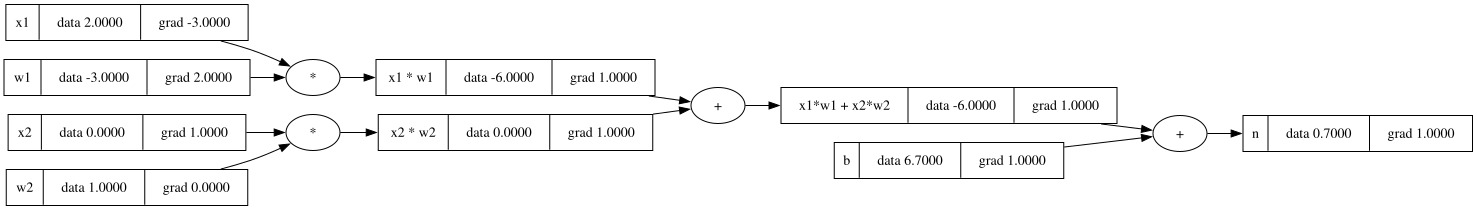

In [13]:
draw_graph(n)

In [14]:
# a simple neuron
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

w1 = Value(-3.0, label='w1')
w2 = Value(1.0 , label='w2')
b = Value(6.7, label='b')

x1w1 = x1*w1; x1w1.label='x1 * w1'
x2w2 = x2*w2; x2w2.label='x2 * w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'

n = x1w1x2w2 + b; n.label='n'

Fontconfig warning: We will not regenerate the cache because some cache files were generated by a newer version (0x2012003) of Fontconfig. Please regenerate the cache with the latest version of Fontconfig to avoid any unexpected behavior. (current version: 0x2012002)


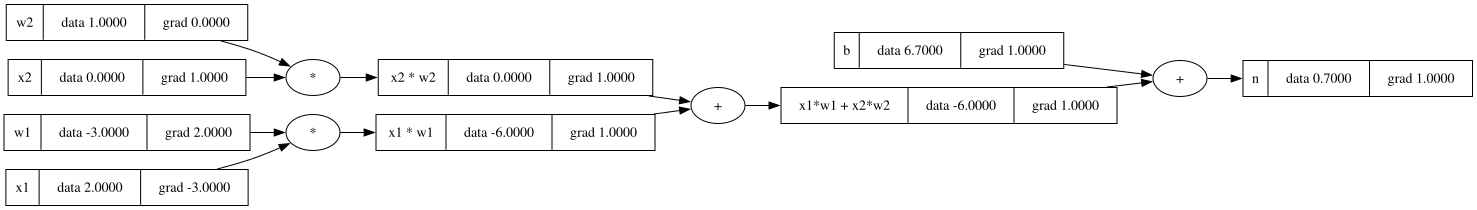

In [15]:
n.backward()
draw_graph(n)